<a href="https://colab.research.google.com/github/sandhiyasivanandanx/Assessment-_SUPERVISED-LEARNING/blob/main/Assessment__SUPERVISED_LEARNING_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**1. Data understanding and exploratory analysis**

•	**Load the CSV and inspect its shape, column names, data types and first few records.**

•	**Identify missing values and check for duplicate rows.**

•	**Report the target-class distribution and at least two useful observations from the data. Use suitable visualisations.**




In [91]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression


In [31]:
import pandas as pd

df = pd.read_csv('/content/drive/MyDrive/Assessment/bank_marketing_assessment_dataset.csv')
df.head()

,customer_age,job,marital_status,education,account_balance,housing_loan,personal_loan,contact_type,contact_month,campaign_contacts,previous_contacts,engagement_score,annual_income_estimate,subscribed
0,69,retired,divorced,secondary,5467.0,no,no,unknown,nov,4,0,8,23029,no
1,21,admin,single,secondary,606.0,no,no,telephone,may,8,0,1,12000,no
2,27,technician,married,tertiary,-314.0,yes,no,cellular,nov,12,0,10,43597,no
3,53,management,single,secondary,1503.0,yes,yes,cellular,nov,6,0,10,24602,no
4,51,management,single,secondary,3037.0,no,no,unknown,jun,5,0,2,27127,no


In [32]:
df.shape

(600, 14)

In [33]:
df.describe()

,customer_age,account_balance,campaign_contacts,previous_contacts,engagement_score,annual_income_estimate
count,600.000000,588.000000,600.000000,600.000000,600.000000,600.0000
mean,38.208333,1535.037415,5.566667,1.015000,4.451667,31805.3650
std,15.387426,2366.916896,2.020485,1.582914,2.938603,17264.0821
min,18.000000,-5418.000000,3.000000,0.000000,1.000000,12000.0000
25%,26.000000,-24.750000,4.000000,0.000000,1.000000,16112.5000
50%,34.000000,1589.500000,5.000000,0.000000,4.000000,29156.0000
75%,49.000000,3042.750000,7.000000,2.000000,7.000000,43444.0000
max,75.000000,9365.000000,13.000000,8.000000,10.000000,108930.0000


In [34]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   customer_age            600 non-null    int64  
 1   job                     600 non-null    object 
 2   marital_status          600 non-null    object 
 3   education               585 non-null    object 
 4   account_balance         588 non-null    float64
 5   housing_loan            600 non-null    object 
 6   personal_loan           600 non-null    object 
 7   contact_type            591 non-null    object 
 8   contact_month           600 non-null    object 
 9   campaign_contacts       600 non-null    int64  
 10  previous_contacts       600 non-null    int64  
 11  engagement_score        600 non-null    int64  
 12  annual_income_estimate  600 non-null    int64  
 13  subscribed              600 non-null    object 
dtypes: float64(1), int64(5), object(8)
memory 

In [37]:
df.isnull().sum()

,0
customer_age,0
job,0
marital_status,0
education,15
account_balance,12
housing_loan,0
personal_loan,0
contact_type,9
contact_month,0
campaign_contacts,0


In [38]:
df.isnull().sum().sum()

np.int64(36)

In [39]:
df.duplicated().sum()

np.int64(0)

In [40]:
df['subscribed'].value_counts()

,count
subscribed,
no,426
yes,174


In [41]:
df['subscribed'].value_counts(normalize=True) * 100

,proportion
subscribed,
no,71.0
yes,29.0


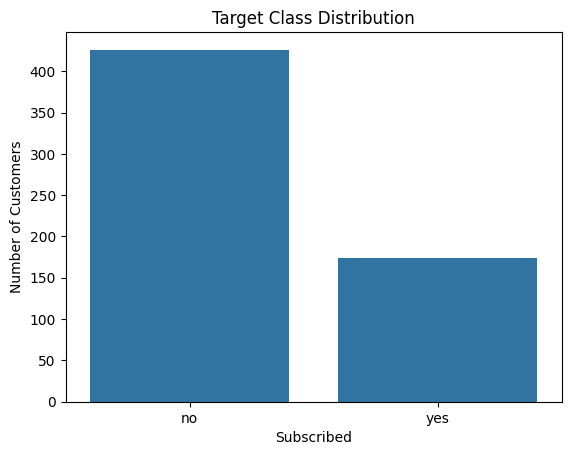

In [45]:
sns.countplot(x='subscribed', data=df)
plt.title('Target Class Distribution')
plt.xlabel('Subscribed')
plt.ylabel('Number of Customers')
plt.show()

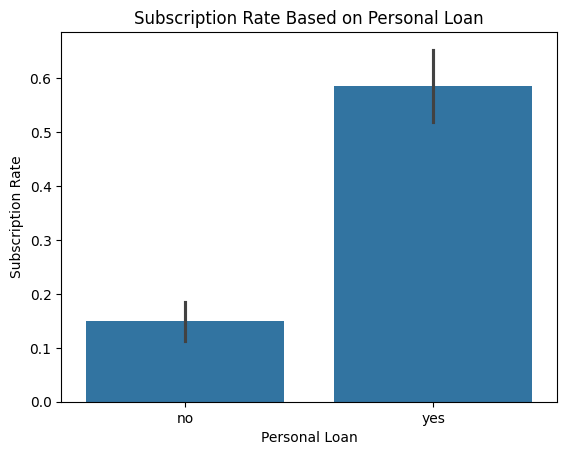

In [46]:
sns.barplot(x='personal_loan', y=df['subscribed'].eq('yes').astype(int), data=df)
plt.title('Subscription Rate Based on Personal Loan')
plt.xlabel('Personal Loan')
plt.ylabel('Subscription Rate')
plt.show()

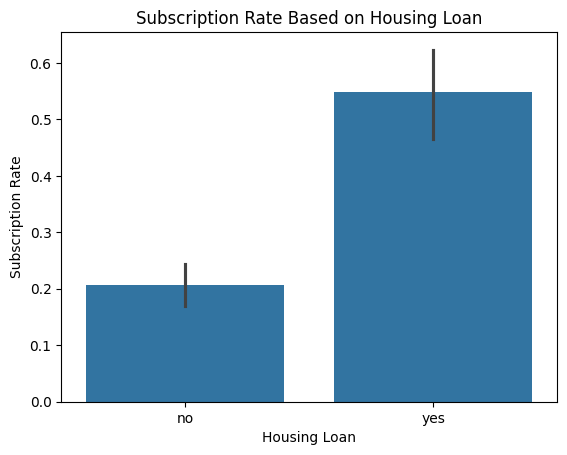

In [47]:
sns.barplot(x='housing_loan', y=df['subscribed'].eq('yes').astype(int), data=df)
plt.title('Subscription Rate Based on Housing Loan')
plt.xlabel('Housing Loan')
plt.ylabel('Subscription Rate')
plt.show()

**2. Data preparation and feature engineering**

•	**Separate the input features (X) and target (y)**.

•	**Split the data into training and test sets using an 80:20 split and a fixed random_state. Use stratification.**

•	**Handle missing values appropriately. Encode categorical features and scale numerical features where appropriate.**

•	**Ensure preprocessing is fitted only on the training data; avoid data leakage.**



In [48]:
X = df.drop('subscribed', axis=1)
y = df['subscribed']

In [51]:
X.head()

,customer_age,job,marital_status,education,account_balance,housing_loan,personal_loan,contact_type,contact_month,campaign_contacts,previous_contacts,engagement_score,annual_income_estimate
0,69,retired,divorced,secondary,5467.0,no,no,unknown,nov,4,0,8,23029
1,21,admin,single,secondary,606.0,no,no,telephone,may,8,0,1,12000
2,27,technician,married,tertiary,-314.0,yes,no,cellular,nov,12,0,10,43597
3,53,management,single,secondary,1503.0,yes,yes,cellular,nov,6,0,10,24602
4,51,management,single,secondary,3037.0,no,no,unknown,jun,5,0,2,27127


In [50]:
y.head()

,subscribed
0,no
1,no
2,no
3,no
4,no


In [52]:
from sklearn.model_selection import train_test_split

In [53]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [54]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (480, 13)
X_test: (120, 13)
y_train: (480,)
y_test: (120,)


In [65]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print(f"Training set shape: {X_train.shape}")
print(f"Test set shape: {X_test.shape}")

Training set shape: (480, 13)
Test set shape: (120, 13)


In [74]:
from sklearn.impute import SimpleImputer
import pandas as pd

num_cols = X_train.select_dtypes(include=['number']).columns
cat_cols = X_train.select_dtypes(include=['object']).columns

num_imputer = SimpleImputer(strategy='median')
X_train_num_imputed = pd.DataFrame(num_imputer.fit_transform(X_train[num_cols]), columns=num_cols, index=X_train.index)
X_test_num_imputed = pd.DataFrame(num_imputer.transform(X_test[num_cols]), columns=num_cols, index=X_test.index)

cat_imputer = SimpleImputer(strategy='most_frequent')
X_train_cat_imputed = pd.DataFrame(cat_imputer.fit_transform(X_train[cat_cols]), columns=cat_cols, index=X_train.index)
X_test_cat_imputed = pd.DataFrame(cat_imputer.transform(X_test[cat_cols]), columns=cat_cols, index=X_test.index)

print("--- MISSING VALUES ARE HANDLED SUCCESSFULLY! ---")

--- MISSING VALUES ARE HANDLED SUCCESSFULLY! ---


In [70]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_num_scaled = pd.DataFrame(scaler.fit_transform(X_train_num_imputed), columns=num_cols, index=X_train.index)
X_test_num_scaled = pd.DataFrame(scaler.transform(X_test_num_imputed), columns=num_cols, index=X_test.index)

print("--- NUMERICAL FEATURES ARE SCALED SUCCESSFULLY! ---")

--- NUMERICAL FEATURES ARE SCALED SUCCESSFULLY! ---


In [75]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
X_train_cat_encoded_raw = encoder.fit_transform(X_train_cat_imputed)
X_test_cat_encoded_raw = encoder.transform(X_test_cat_imputed)

encoded_cols = encoder.get_feature_names_out(cat_cols)
X_train_cat_encoded = pd.DataFrame(X_train_cat_encoded_raw, columns=encoded_cols, index=X_train.index)
X_test_cat_encoded = pd.DataFrame(X_test_cat_encoded_raw, columns=encoded_cols, index=X_test.index)

print("--- CATEGORICAL FEATURES ARE ENCODED SUCCESSFULLY! ---")

--- CATEGORICAL FEATURES ARE ENCODED SUCCESSFULLY! ---


In [77]:
X_train_final = pd.concat([X_train_num_scaled, X_train_cat_encoded], axis=1)
X_test_final = pd.concat([X_test_num_scaled, X_test_cat_encoded], axis=1)

X_train_preprocessed = X_train_final.values
X_test_preprocessed = X_test_final.values
print(f"THE FINAL TRAINING SHAPE : {X_train_final.shape}")
print(f"THE FINAL TESTING SHAPE : {X_test_final.shape}")

THE FINAL TRAINING SHAPE : (480, 31)
THE FINAL TESTING SHAPE : (120, 31)


In [79]:
from sklearn.compose import make_column_transformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import make_pipeline

num_cols = X.select_dtypes(include=['int64', 'float64']).columns
cat_cols = X.select_dtypes(include=['object']).columns

preprocessor = make_column_transformer(
    (make_pipeline(SimpleImputer(strategy='median'), StandardScaler()), num_cols),
    (make_pipeline(SimpleImputer(strategy='most_frequent'), OneHotEncoder(handle_unknown='ignore', sparse_output=False)), cat_cols)
)

X_train_preprocessed = preprocessor.fit_transform(X_train)
X_test_preprocessed = preprocessor.transform(X_test)

print("--- THE PRE-PROCESSING IS COMPLETED SUCCESSFULLY WITHOUT ANY DATA LEAKAGE. ---")

--- THE PRE-PROCESSING IS COMPLETED SUCCESSFULLY WITHOUT ANY DATA LEAKAGE. ---


**3. Model building**

•	**Build a Logistic Regression classification model.**

•	**Build a Decision Tree or Random Forest classification model.**

•	**Use a reproducible preprocessing/model pipeline where appropriate.**


In [80]:
from sklearn.linear_model import LinearRegression

In [84]:
log_reg = LogisticRegression(random_state=42, max_iter=1000)
log_reg.fit(X_train_preprocessed, y_train)
print("---THE LOGISTIC REGRESSION MODEL IS SUCCESSFULLY TRAINED! ---")

---THE LOGISTIC REGRESSION MODEL IS SUCCESSFULLY TRAINED! ---


In [85]:
from sklearn.tree import DecisionTreeClassifier

In [87]:
dt_classifier = DecisionTreeClassifier(random_state=42, max_depth=5)
dt_classifier.fit(X_train_preprocessed, y_train)
print("--- THE DECISION TREE CLASSIFIER IS SUCCESSFULLY TRAINED! ---")

--- THE DECISION TREE CLASSIFIER IS SUCCESSFULLY TRAINED! ---


**4. Model evaluation and comparison**

•	**Evaluate both models on the test set using accuracy, precision, recall and F1-score.**

•	**Generate and interpret a confusion matrix for each model.**

•	**Compare the models and explain which one you would recommend for this business problem. Consider the cost of missing likely subscribers as well as overall performance.**


In [93]:
from sklearn.metrics import precision_score, recall_score
from sklearn.metrics import accuracy_score, f1_score

In [100]:
print("--- LOGISTIC REGRESSION ---")
print("Accuracy Score:", accuracy_score(y_test, log_reg.predict(X_test_preprocessed)))
print("Precision Score:", precision_score(y_test, log_reg.predict(X_test_preprocessed), pos_label='yes'))
print("Recall Score:", recall_score(y_test, log_reg.predict(X_test_preprocessed), pos_label='yes'))
print("F1 Score:", f1_score(y_test, log_reg.predict(X_test_preprocessed), pos_label='yes'))

--- LOGISTIC REGRESSION ---
Accuracy Score: 0.85
Precision Score: 0.8695652173913043
Recall Score: 0.5714285714285714
F1 Score: 0.6896551724137931


In [101]:
print("--- DECISION TREE CLASSIFIER ---")
print("Accuracy Score:", accuracy_score(y_test, dt_classifier.predict(X_test_preprocessed)))
print("Precision Score:", precision_score(y_test, dt_classifier.predict(X_test_preprocessed), pos_label='yes'))
print("Recall Score:", recall_score(y_test, dt_classifier.predict(X_test_preprocessed), pos_label='yes'))
print("F1 Score:", f1_score(y_test, dt_classifier.predict(X_test_preprocessed), pos_label='yes'))

--- DECISION TREE CLASSIFIER ---
Accuracy Score: 0.8666666666666667
Precision Score: 0.8518518518518519
Recall Score: 0.6571428571428571
F1 Score: 0.7419354838709677


In [98]:
from sklearn.metrics import confusion_matrix

In [102]:
print("--- LOGISTIC REGRESSION CONFUSION MATRIX ---")
print(confusion_matrix(y_test, log_reg.predict(X_test_preprocessed)))

--- LOGISTIC REGRESSION CONFUSION MATRIX ---
[[82  3]
 [15 20]]


In [104]:
print("--- DECISION TREE CLASSIFIER CONFUSION MATRIX ---")
print(confusion_matrix(y_test, dt_classifier.predict(X_test_preprocessed)))

--- DECISION TREE CLASSIFIER CONFUSION MATRIX ---
[[81  4]
 [12 23]]


### **Recommendation: Decision Tree Classifier**

The Decision Tree Classifier is the preferred model for the following reasons:

1\. **Higher Recall:** The Decision Tree successfully identified 23 out of 35 actual subscribers, compared to 20 identified by Logistic Regression. This helps reduce missed potential subscribers by 3, lowering False Negatives from 15 to 12.

2\. **Better Overall Performance (F1-Score):** The Decision Tree achieved a higher F1-score of **74.19%**, compared to **68.97%** for Logistic Regression, indicating a better balance between precision and recall. It also maintained a test accuracy of **86.67%**.

**5. Business interpretation and prediction**

•	**Identify the most influential features using a suitable model interpretation method. Explain the limitations of the interpretation.**

•	**Use the selected model to predict subscription for five sample customers from the test set. Display the predicted class and, if available, probability.**

•	**Write a short business conclusion (3–5 sentences) summarising your model choice, evaluation and one improvement you would try next.**


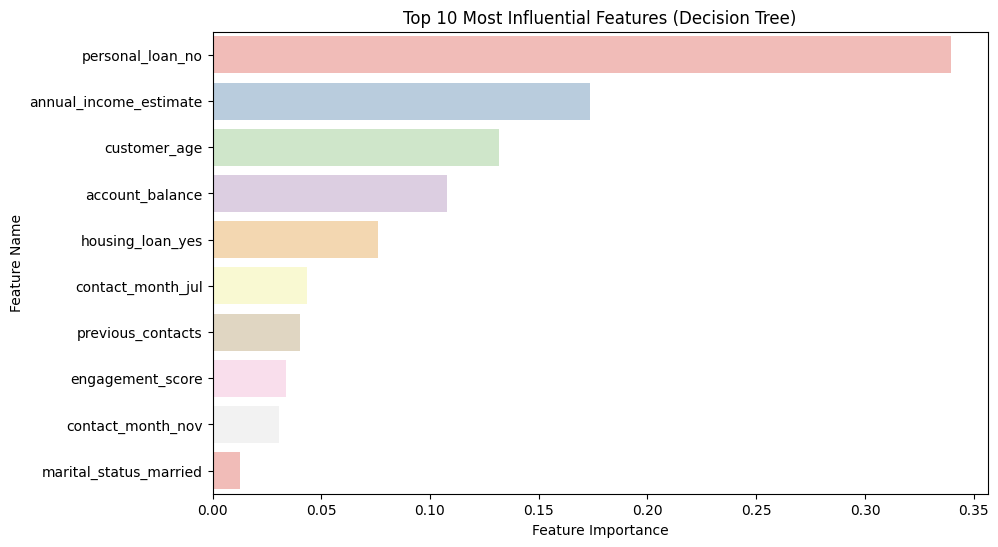

In [105]:
feature_names = num_cols.tolist() + encoded_cols.tolist()
importances = dt_classifier.feature_importances_

feature_importance_df = pd.DataFrame({'Feature': feature_names,'Importance': importances}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(data=feature_importance_df.head(10), x='Importance', y='Feature',hue = 'Feature',palette='Pastel1')
plt.title('Top 10 Most Influential Features (Decision Tree)')
plt.xlabel('Feature Importance')
plt.ylabel('Feature Name')
plt.show()

**Limitations of the Interpretation :**

1. **Correlation vs. Causation:** High feature importance means that a feature plays a significant role in making decisions within the decision tree. However, it does not necessarily mean that the feature directly causes the outcome.

2. **Instability (High Variance):** Decision Trees are sensitive to changes in training data. Even small changes in the dataset can produce a different tree structure and affect the feature importance rankings.

3. **Bias Towards High Cardinality:** Decision Trees may favor features with a large number of unique values or categories because they provide more possible splitting options.

In [106]:
sample_indices = X_test.index[:5]
samples_preprocessed = X_test_preprocessed[:5]

predicted_classes = dt_classifier.predict(samples_preprocessed)
predicted_probabilities = dt_classifier.predict_proba(samples_preprocessed)[:, 1]

samples_df = X_test.loc[sample_indices].copy()
samples_df['Actual Subscribed'] = y_test.loc[sample_indices].map({0: 'no', 1: 'yes'})
samples_df['Predicted Class'] = ['yes' if p == 1 else 'no' for p in predicted_classes]
samples_df['Probability of Yes'] = predicted_probabilities

display(samples_df[['customer_age', 'job', 'Actual Subscribed', 'Predicted Class', 'Probability of Yes']])

,customer_age,job,Actual Subscribed,Predicted Class,Probability of Yes
269,54,blue-collar,NaN,no,0.000000
70,18,admin,NaN,no,1.000000
376,57,management,NaN,no,0.036199
543,64,services,NaN,no,1.000000
429,23,admin,NaN,no,0.036199


### **Business Conclusion**

To enhance the marketing strategy for term deposit subscriptions, I compared the performance of Logistic Regression and Decision Tree Classifier models. The Decision Tree Classifier was selected as the better-performing model, achieving a recall of **65.71%** (correctly identifying 23 out of 35 actual subscribers) and an F1-score of **74.19%**. This makes it more effective at identifying potential subscribers and reducing the chances of missing interested customers.
